# Detecção de buracos em vias públicas com YOLO11s — ViaAlerta


## 1. Bibliotecas e ambiente

In [25]:
from pathlib import Path
from importlib.metadata import version
import gc
import hashlib
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from PIL import Image, ImageDraw
from torchmetrics.detection import MeanAveragePrecision
from torchvision.ops import box_iou
from tqdm.auto import tqdm
from ultralytics import YOLO

EXIGIR_GPU = True
if EXIGIR_GPU and not torch.cuda.is_available():
    raise RuntimeError('GPU não encontrada. Confira a instalação do PyTorch com CUDA.')
DISPOSITIVO_YOLO = 0 if torch.cuda.is_available() else 'cpu'
print('Usando:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Usando: NVIDIA GeForce RTX 5070


## 2. Caminhos


In [26]:
PASTA_ATUAL = Path.cwd().resolve()
for pasta in (PASTA_ATUAL, *PASTA_ATUAL.parents):
    if (pasta / 'api/app.py').is_file() and (pasta / 'notebooks').is_dir():
        PROJETO = pasta / 'notebooks'
        break
else:
    raise FileNotFoundError(
        'Abra o notebook na pasta do projeto ViaAlerta ou em uma de suas subpastas.'
    )

BASE = PROJETO / 'dados/preparados_buracos'
RELATORIOS = PROJETO / 'relatorios/buracos_consolidado'
NOME_TREINO = 'buracos_aug_nativo_01'
PASTA_TREINO = PROJETO / 'treinamentos' / NOME_TREINO
PASTA_YOLO = PASTA_TREINO / 'yolo_300ep-3'
PASTA_RESULTADOS = PASTA_TREINO / 'avaliacao'
ARQUIVO_YAML = PASTA_TREINO / 'dados.yaml'

DIVISOES = ['treino', 'validacao', 'teste']
EXTENSOES = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}


CONFIANCA = 0.25
IOU_ACERTO = 0.50

assert BASE.is_dir(), f'Dataset não encontrado: {BASE}'
RELATORIOS.mkdir(parents=True, exist_ok=True)
PASTA_TREINO.mkdir(parents=True, exist_ok=True)

ambiente = {nome: version(nome) for nome in ['torch', 'torchvision', 'ultralytics', 'torchmetrics', 'numpy', 'pandas']}
ambiente['gpu'] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
(PASTA_TREINO / 'ambiente.json').write_text(json.dumps(ambiente, indent=2), encoding='utf-8')
print('Dataset:', BASE)
print('Experimento:', PASTA_TREINO)

Dataset: .\notebooks\dados\preparados_buracos
Experimento: .\notebooks\treinamentos\buracos_aug_nativo_01


## 3. Qualidade dos dados

A verificação **só lê** o dataset e gera `verificacao_dados.csv`, com uma linha por achado:

| Severidade | Exemplos | Efeito |
|---|---|---|
| **erro** | imagem sem label (ou o contrário), imagem ilegível, linha fora do formato YOLO, classe ≠ 0, valor não numérico, coordenada fora de [0, 1], caixa sem área ou que ultrapassa a imagem, divisão vazia, imagem idêntica em duas divisões, grupo do manifesto em mais de uma divisão, `sha256_pixels` repetido | interrompe a execução |
| **aviso** | linhas repetidas num label, imagem idêntica dentro da mesma divisão, manifesto com outra contagem ou sem alguma coluna | só informa |

**Label vazio é uma imagem anotada sem buraco (negativo) e não é erro.** Label ausente é erro.
Nada é corrigido automaticamente: revise o relatório antes de treinar.

In [27]:
def listar_imagens(divisao):
    """Lista as imagens de uma divisão do dataset original, em ordem alfabética."""
    return sorted(p for p in (BASE / 'images' / divisao).iterdir() if p.suffix.lower() in EXTENSOES)


def ler_caixas(imagem):
    """Lê o label YOLO de uma imagem (classe, cx, cy, w, h) e valida o conteúdo.

    Label vazio devolve um array (0, 5): imagem sem buraco.
    """
    caminho = BASE / 'labels' / imagem.parent.name / f'{imagem.stem}.txt'
    texto = caminho.read_text(encoding='utf-8-sig').strip()
    if not texto:
        return np.empty((0, 5), dtype=np.float32)
    linhas = [list(map(float, linha.split())) for linha in texto.splitlines() if linha.strip()]
    if any(len(linha) != 5 for linha in linhas):
        raise ValueError('Esperadas cinco colunas por linha (classe cx cy w h).')
    caixas = np.array(linhas, dtype=np.float32)
    if not np.isfinite(caixas).all():
        raise ValueError('Valor não numérico ou infinito.')
    if (caixas[:, 0] != 0).any():
        raise ValueError('Classe diferente de 0.')
    if (caixas[:, 1:] < 0).any() or (caixas[:, 1:] > 1).any():
        raise ValueError('Coordenada fora do intervalo [0, 1].')
    if (caixas[:, 3:] <= 0).any():
        raise ValueError('Caixa sem largura ou altura.')
    cx, cy, w, h = caixas[:, 1:].T
    cantos = np.stack([cx - w/2, cy - h/2, cx + w/2, cy + h/2], axis=1)
    if (cantos < -1e-5).any() or (cantos > 1 + 1e-5).any():
        raise ValueError('Caixa ultrapassa os limites da imagem.')
    return caixas


def caixas_em_pixels(caixas, largura, altura):
    """Converte (classe, cx, cy, w, h) normalizados em XYXY de pixels, float32 e (N, 4).

    Sem caixas devolve um array vazio (0, 4); não cria caixas artificiais.
    """
    if largura <= 0 or altura <= 0:
        raise ValueError(f'Dimensões inválidas: {largura}x{altura}')
    if len(caixas) == 0:
        return np.empty((0, 4), dtype=np.float32)
    cx, cy, w, h = (caixas[:, i] for i in range(1, 5))
    xyxy = np.stack([(cx - w/2) * largura, (cy - h/2) * altura,
                     (cx + w/2) * largura, (cy + h/2) * altura], axis=1)
    xyxy[:, [0, 2]] = xyxy[:, [0, 2]].clip(0, largura)
    xyxy[:, [1, 3]] = xyxy[:, [1, 3]].clip(0, altura)
    if ((xyxy[:, 2] - xyxy[:, 0]) <= 0).any() or ((xyxy[:, 3] - xyxy[:, 1]) <= 0).any():
        raise ValueError('Caixa sem largura ou altura após o recorte à imagem.')
    return xyxy.astype(np.float32)


def validar_dados():
    """Confere o dataset sem alterá-lo, salva o relatório e interrompe se houver erro.

    Retorna as anotações: {divisao: {nome_da_imagem: caixas}}.
    """
    anotacoes, achados, hashes = {}, [], {}
    for divisao in DIVISOES:
        imagens = listar_imagens(divisao)
        if not imagens:
            achados.append(('erro', divisao, '', 'Divisão sem imagens.'))
        labels = {p.stem for p in (BASE / 'labels' / divisao).glob('*.txt')}
        for nome in sorted({p.stem for p in imagens} ^ labels):
            achados.append(('erro', divisao, nome, 'Imagem sem label ou label sem imagem.'))
        anotacoes[divisao] = {}
        for caminho in tqdm(imagens, desc=f'Verificando {divisao}'):
            try:
                with Image.open(caminho) as imagem:
                    imagem.verify()
                caixas = ler_caixas(caminho)
                anotacoes[divisao][caminho.stem] = caixas
                if len(caixas) > 1 and len(np.unique(caixas, axis=0)) < len(caixas):
                    achados.append(('aviso', divisao, caminho.name, 'Linhas repetidas no label.'))
                hashes.setdefault(hashlib.sha256(caminho.read_bytes()).hexdigest(), []).append((divisao, caminho.name))
            except Exception as erro:
                achados.append(('erro', divisao, caminho.name, str(erro)))

    for copias in hashes.values():
        if len(copias) > 1:
            entre_divisoes = len({d for d, _ in copias}) > 1
            achados.append(('erro' if entre_divisoes else 'aviso', copias[0][0], copias[0][1],
                            f"Imagem idêntica a {[n for _, n in copias[1:]]} "
                            f"({'divisões diferentes: vazamento' if entre_divisoes else 'mesma divisão'})."))

    arquivo_manifesto = BASE / 'manifesto.csv'
    if arquivo_manifesto.exists():
        manifesto = pd.read_csv(arquivo_manifesto)
        if len(manifesto) != sum(len(a) for a in anotacoes.values()):
            achados.append(('aviso', '', 'manifesto.csv', 'Quantidade de linhas diferente da de imagens.'))
        if 'sha256_pixels' not in manifesto.columns:
            achados.append(('aviso', '', 'manifesto.csv', 'Coluna sha256_pixels ausente.'))
        elif not manifesto.sha256_pixels.is_unique:
            achados.append(('erro', '', 'manifesto.csv', 'sha256_pixels repetido: o manifesto registra imagens repetidas.'))
        for coluna in ['group_id', 'visual_group']:
            if {coluna, 'split'} <= set(manifesto.columns):
                cruzam = int((manifesto.groupby(coluna).split.nunique() > 1).sum())
                if cruzam:
                    achados.append(('erro', '', 'manifesto.csv', f'{cruzam} valor(es) de {coluna} em mais de uma divisão (vazamento).'))
            else:
                achados.append(('aviso', '', 'manifesto.csv', f'Coluna {coluna} ou split ausente: vazamento não verificado.'))
    else:
        achados.append(('aviso', '', 'manifesto.csv', 'Manifesto ausente: duplicatas e grupos não verificados.'))

    relatorio = pd.DataFrame(achados, columns=['severidade', 'divisao', 'arquivo', 'detalhe'])
    relatorio.to_csv(RELATORIOS / 'verificacao_dados.csv', index=False)
    print(f"{(relatorio.severidade == 'erro').sum()} erro(s), {(relatorio.severidade == 'aviso').sum()} aviso(s). "
          f"Relatório: {RELATORIOS / 'verificacao_dados.csv'}")
    if len(relatorio):
        display(relatorio.head(20))
    if (relatorio.severidade == 'erro').any():
        raise ValueError('Há erros nos dados: revise verificacao_dados.csv antes de continuar.')
    return anotacoes


anotacoes = validar_dados()

Verificando treino:   0%|          | 0/5269 [00:00<?, ?it/s]

Verificando validacao:   0%|          | 0/1091 [00:00<?, ?it/s]

Verificando teste:   0%|          | 0/564 [00:00<?, ?it/s]

0 erro(s), 0 aviso(s). Relatório: .\notebooks\relatorios\buracos_consolidado\verificacao_dados.csv


## 4. Análise exploratória

O perfil mostra imagens com e sem buraco, caixas por imagem e o tamanho típico de um
buraco (área da caixa em % da imagem). Buracos muito pequenos costumam ser os mais difíceis.

,imagens,com_buraco,sem_buraco,caixas,caixas_por_imagem,area_mediana_pct
divisao,,,,,,
treino,5269,4448,821,10146,1.93,0.931
validacao,1091,845,246,1474,1.35,0.516
teste,564,421,143,708,1.26,0.498


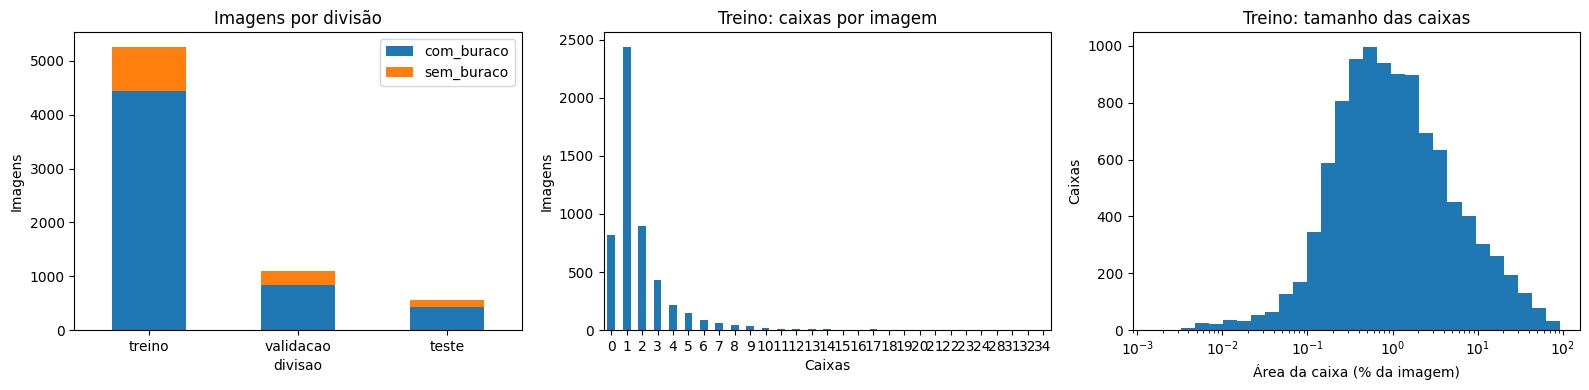

In [28]:
def perfil_dados(anotacoes):
    """Tabela por divisão: imagens com/sem buraco, caixas e área mediana das caixas (%)."""
    linhas = []
    for divisao, por_imagem in anotacoes.items():
        n_caixas = np.array([len(c) for c in por_imagem.values()])
        areas = np.concatenate([c[:, 3] * c[:, 4] for c in por_imagem.values()] or [np.empty(0)])
        linhas.append({
            'divisao': divisao, 'imagens': len(n_caixas),
            'com_buraco': int((n_caixas > 0).sum()), 'sem_buraco': int((n_caixas == 0).sum()),
            'caixas': int(n_caixas.sum()),
            'caixas_por_imagem': round(float(n_caixas.mean()), 2) if len(n_caixas) else np.nan,
            'area_mediana_pct': round(float(np.median(areas)) * 100, 3) if areas.size else np.nan,
        })
    return pd.DataFrame(linhas).set_index('divisao')


def plotar_perfil(perfil, caixas_treino):
    """Três gráficos: imagens por divisão, caixas por imagem e tamanho das caixas (treino)."""
    fig, eixos = plt.subplots(1, 3, figsize=(16, 4))
    perfil[['com_buraco', 'sem_buraco']].plot.bar(ax=eixos[0], stacked=True, rot=0,
                                                  title='Imagens por divisão', ylabel='Imagens')
    por_imagem = pd.Series([len(c) for c in caixas_treino])
    if por_imagem.empty:
        eixos[1].text(0.5, 0.5, 'Sem imagens de treino.', ha='center', va='center')
        eixos[1].axis('off')
    else:
        por_imagem.value_counts().sort_index().plot.bar(ax=eixos[1], rot=0, title='Treino: caixas por imagem',
                                                        xlabel='Caixas', ylabel='Imagens')
    areas = np.concatenate([c[:, 3] * c[:, 4] for c in caixas_treino] or [np.empty(0)]) * 100
    areas = areas[np.isfinite(areas) & (areas > 0)]
    if areas.size == 0:
        eixos[2].text(0.5, 0.5, 'Sem caixas válidas para o histograma.', ha='center', va='center')
        eixos[2].axis('off')
    elif areas.min() == areas.max():
        eixos[2].text(0.5, 0.5, f'Todas as caixas têm a mesma área ({areas[0]:.3f}% da imagem):\n'
                      'sem variação para um histograma.', ha='center', va='center')
        eixos[2].axis('off')
    else:
        eixos[2].hist(areas, bins=np.logspace(np.log10(areas.min()), np.log10(areas.max()), 30))
        eixos[2].set(xscale='log', title='Treino: tamanho das caixas',
                     xlabel='Área da caixa (% da imagem)', ylabel='Caixas')
    plt.tight_layout()
    return fig


perfil = perfil_dados(anotacoes)
perfil.to_csv(RELATORIOS / 'perfil_dados.csv')
display(perfil)
plotar_perfil(perfil, list(anotacoes['treino'].values())).savefig(RELATORIOS / 'perfil_dados.png', dpi=150)
plt.show()

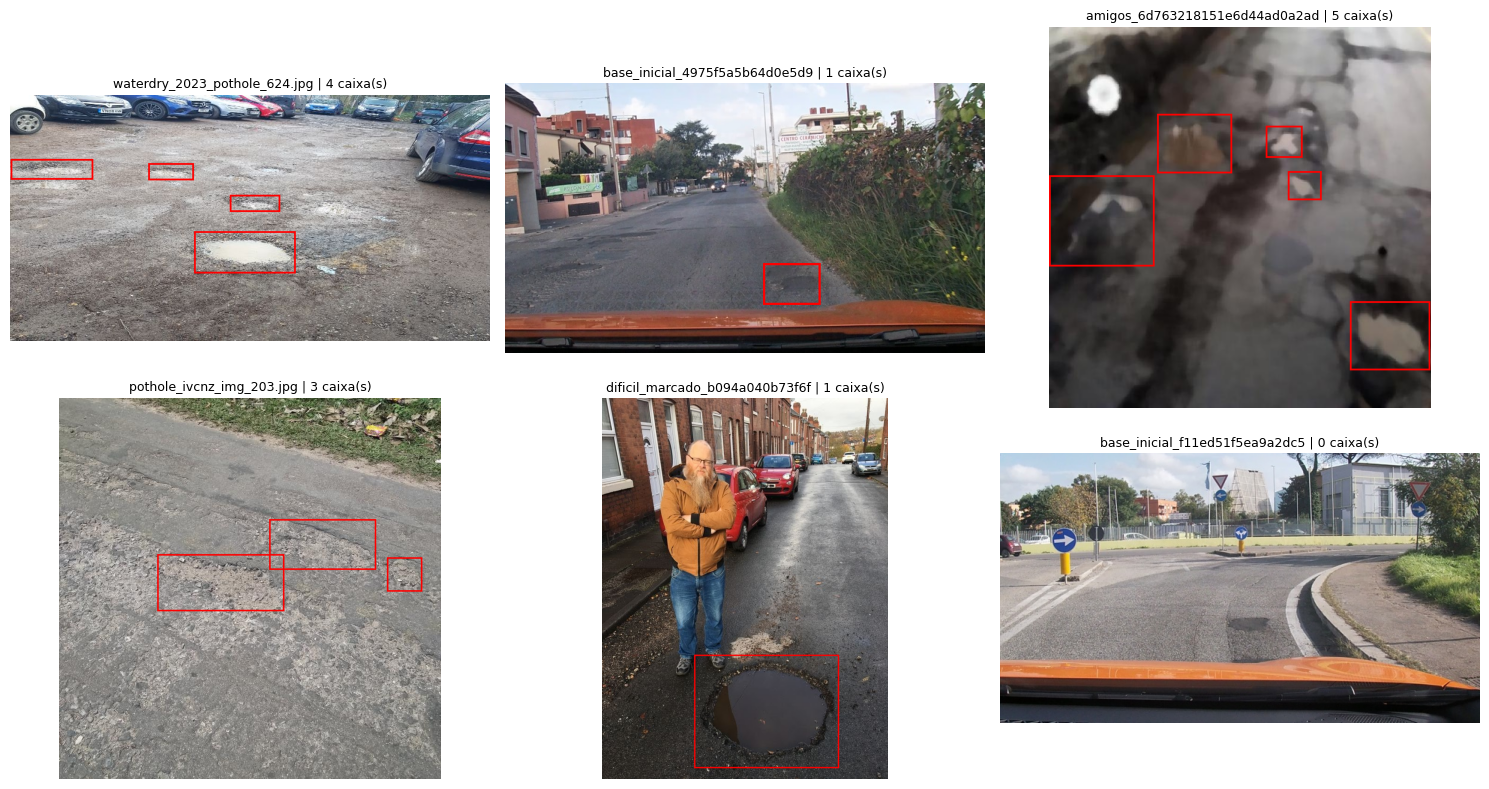

In [29]:

imagens_treino = listar_imagens('treino')
amostra = random.Random(42).sample(imagens_treino, min(6, len(imagens_treino)))
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
for eixo in eixos.flat:
    eixo.axis('off')
for eixo, caminho in zip(eixos.flat, amostra):
    with Image.open(caminho) as arquivo:
        imagem = arquivo.convert('RGB')
    desenho = ImageDraw.Draw(imagem)
    for caixa in caixas_em_pixels(anotacoes['treino'][caminho.stem], imagem.width, imagem.height):
        desenho.rectangle(caixa.tolist(), outline='red', width=3)
    eixo.imshow(imagem)
    eixo.set_title(f'{caminho.name[:30]} | {len(anotacoes["treino"][caminho.stem])} caixa(s)', fontsize=9)
plt.tight_layout()
plt.savefig(RELATORIOS / 'amostra_anotacoes.png', dpi=150)
plt.show()

## 5. Dataset YOLO e Data Augmentation nativo

O `data.yaml` aponta para o dataset original (`images/treino`, `images/validacao`,
`images/teste`) e fica na pasta do experimento, fora do dataset.

### Augmentation do Ultralytics

Não há mais cópias de imagens em disco. Durante o treino, **a cada época e a cada
imagem**, o Ultralytics sorteia as transformações e atualiza as caixas junto. Usamos
os **padrões da versão instalada** (os valores efetivos ficam em `yolo/args.yaml` e
são copiados para `treinamento.json`). Em geral, no detector:

| Transformação | Parâmetro | Por que ajuda em fotos de rua |
|---|---|---|
| Matiz, saturação e brilho (HSV) | `hsv_h`, `hsv_s`, `hsv_v` | luz do dia, sombra, céu nublado, câmeras diferentes |
| Translação | `translate` | o buraco não está sempre no centro |
| Escala | `scale` | distâncias diferentes até o buraco |
| Espelhamento horizontal | `fliplr` | o buraco não tem lado; dobra as variações |
| Mosaic (4 imagens numa) | `mosaic` | mais contexto e buracos pequenos; **desligado nas últimas 10 épocas** (`close_mosaic`) |

Rotação, cisalhamento, perspectiva, espelhamento vertical, mixup e copy-paste ficam
com o padrão (desligados no detector): giram ou deformam a rua de forma pouco realista.

**Validação e teste não recebem augmentation**: o Ultralytics só aplica essas transformações
no conjunto de treino. As imagens de validação e teste só são redimensionadas (letterbox).

Primeiro treinamos com os padrões; só se a validação indicar overfitting ou erros
sistemáticos (por exemplo, buracos pequenos) vale propor ajustes, e sempre pela validação.

In [30]:
ARQUIVO_YAML.write_text(yaml.safe_dump({
    'path': BASE.resolve().as_posix(), 'train': 'images/treino',
    'val': 'images/validacao', 'test': 'images/teste', 'names': {0: 'buraco'},
}, sort_keys=False), encoding='utf-8')
print(ARQUIVO_YAML.read_text(encoding='utf-8'))

path: ./notebooks/dados/preparados_buracos
train: images/treino
val: images/validacao
test: images/teste
names:
  0: buraco



## 6. Treinamento do YOLO11s

In [31]:

ARQUIVO_YAML = PASTA_TREINO / 'dados.yaml'
if not ARQUIVO_YAML.is_file():
    ARQUIVO_YAML.parent.mkdir(parents=True, exist_ok=True)
    ARQUIVO_YAML.write_text(yaml.safe_dump({
        'path': BASE.resolve().as_posix(), 'train': 'images/treino',
        'val': 'images/validacao', 'test': 'images/teste', 'names': {0: 'buraco'},
    }, sort_keys=False), encoding='utf-8')

if PASTA_YOLO.exists():
    raise FileExistsError('Esse treino YOLO já existe. Troque NOME_TREINO.')

modelo_yolo = YOLO('yolo11s.pt')

inicio = time.perf_counter()
modelo_yolo.train(
    data=str(ARQUIVO_YAML),
    epochs=300,
    batch=0.80,
    imgsz=640,
    seed=42,
    patience=20,
    amp=True,
    device=DISPOSITIVO_YOLO,
    workers=0,
    project=str(PASTA_TREINO),
    name='yolo_300ep-3',
    plots=True,
)
horas = (time.perf_counter() - inicio) / 3600


PASTA_YOLO = Path(modelo_yolo.trainer.save_dir)


args = yaml.safe_load((PASTA_YOLO / 'args.yaml').read_text(encoding='utf-8'))
epocas_executadas = len(pd.read_csv(PASTA_YOLO / 'results.csv'))
chaves_augmentation = ['hsv_h', 'hsv_s', 'hsv_v', 'degrees', 'translate', 'scale', 'shear', 'perspective',
                       'flipud', 'fliplr', 'mosaic', 'mixup', 'copy_paste', 'close_mosaic']
(PASTA_TREINO / 'treinamento.json').write_text(json.dumps({
    'horas': horas, 'epocas_maximas': args['epochs'], 'epocas_executadas': epocas_executadas,
    'parou_antes': epocas_executadas < args['epochs'],
    'seed': args['seed'], 'patience': args['patience'], 'batch': args['batch'], 'imgsz': args['imgsz'],
    'otimizador': args.get('optimizer'), 'augmentation_efetiva': {k: args.get(k) for k in chaves_augmentation},
    'hash_manifesto': hashlib.sha256((BASE / 'manifesto.csv').read_bytes()).hexdigest() if (BASE / 'manifesto.csv').exists() else None,
}, indent=2), encoding='utf-8')
print(f'Tempo: {horas:.2f} h | épocas: {epocas_executadas} de até {args["epochs"]}')

del modelo_yolo
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

New https://pypi.org/project/ultralytics/8.4.201 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.198  Python-3.11.9 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070, 12199MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=0.8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=.\notebooks\treinamentos\buracos_aug_nativo_01\dados.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=

FileNotFoundError: '.\notebooks\treinamentos\buracos_aug_nativo_01\dados.yaml' does not exist

In [33]:
PASTA_YOLO = PASTA_TREINO / 'yolo_300ep-3'
ARQUIVO_YAML = PASTA_TREINO / 'dados.yaml'


if 'modelo_yolo' in globals():
    del modelo_yolo
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


modelo_yolo = YOLO(str(PASTA_YOLO / 'weights/best.pt'))

validacao_yolo = modelo_yolo.val(
    data=str(ARQUIVO_YAML),
    split='val',
    imgsz=640,
    device=DISPOSITIVO_YOLO,
    workers=0,
    plots=True,
    project=str(PASTA_TREINO),
    name='validacao_recuperada',
)

Ultralytics 8.4.198  Python-3.11.9 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070, 12199MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1534.7±1251.0 MB/s, size: 626.8 KB)
val: Scanning .\notebooks\dados\preparados_buracos\labels\validacao.cache... 1091 images, 246 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1091/1091  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 7.5it/s 9.2s0.1ss
                   all       1091       1474       0.61      0.514      0.549      0.239
Speed: 0.1ms preprocess, 2.0ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to .\notebooks\treinamentos\buracos_aug_nativo_01\validacao_recuperada


In [34]:

PASTA_YOLO = PASTA_TREINO / 'yolo_300ep-3'

for arquivo in ['args.yaml', 'results.csv', 'weights/best.pt']:
    if not (PASTA_YOLO / arquivo).is_file():
        raise FileNotFoundError(
            f'Arquivo não encontrado: {PASTA_YOLO / arquivo}. '
            'Confira o nome da pasta do treinamento nesta célula.'
        )

args = yaml.safe_load((PASTA_YOLO / 'args.yaml').read_text(encoding='utf-8'))
epocas_executadas = len(pd.read_csv(PASTA_YOLO / 'results.csv'))

print('Treinamento selecionado:', PASTA_YOLO)
print(f'Épocas executadas: {epocas_executadas}')
print(f'Pesos salvos em: {PASTA_YOLO / "weights" / "best.pt"}')


Treinamento selecionado: .\notebooks\treinamentos\buracos_aug_nativo_01\yolo_300ep-3
Épocas executadas: 77
Pesos salvos em: .\notebooks\treinamentos\buracos_aug_nativo_01\yolo_300ep-3\weights\best.pt


## 7. Validação do modelo

Recarregamos `best.pt` e avaliamos **somente a validação**. Cada imagem é lida do dataset
original e as caixas previstas voltam em pixels da imagem original.

- **mAP50 e mAP50–95:** TorchMetrics, usando todas as previsões desde confiança 0,001,
  com IoU de 0,50 a 0,95.
- **Precision, recall e F1:** só previsões com confiança ≥ `CONFIANCA`; uma previsão acerta (TP)
  se tiver IoU ≥ `IOU_ACERTO` com uma caixa real **ainda não usada**; senão é falso positivo (FP).
  Caixa real sem acerto é buraco perdido (FN).
- **Acurácia de presença por imagem:** havia (ou não) buraco na imagem e o modelo alertou
  (ou não)? **Não mede a localização das caixas**, por isso não é acurácia de detecção.

Na previsão usamos os padrões do Ultralytics para a supressão de caixas repetidas
(`iou=0.7`, `max_det=300`), os mesmos da validação interna que escolheu o `best.pt`.
O TorchMetrics considera as 100 melhores caixas por imagem para o mAP.

In [35]:
def carregar_alvos(imagens):
    """Caixas reais em pixels no formato do TorchMetrics (buraco = classe 0); (0, 4) se não houver."""
    alvos = []
    for caminho in imagens:
        with Image.open(caminho) as arquivo:
            largura, altura = arquivo.size
        xyxy = caixas_em_pixels(ler_caixas(caminho), largura, altura)
        alvos.append({'boxes': torch.from_numpy(xyxy), 'labels': torch.zeros(len(xyxy), dtype=torch.int64)})
    return alvos


def prever(modelo, imagens, lote=16):
    """Caixas previstas (XYXY em pixels da imagem original) com confiança mínima de 0,001."""
    previsoes = []
    for i in tqdm(range(0, len(imagens), lote), desc='Prevendo'):
        arrays = []
        for caminho in imagens[i:i + lote]:
            with Image.open(caminho) as arquivo:
                arrays.append(np.asarray(arquivo.convert('RGB'))[:, :, ::-1].copy())
        saidas = modelo.predict(arrays, imgsz=640, conf=0.001, iou=0.7, max_det=300,
                                device=DISPOSITIVO_YOLO, verbose=False)
        previsoes += [{'boxes': s.boxes.xyxy.cpu().float(), 'scores': s.boxes.conf.cpu().float(),
                       'labels': s.boxes.cls.cpu().long()} for s in saidas]
    return previsoes


def parear_caixas(previsto, real):
    """Pareia as previsões de uma imagem com as caixas reais. Retorna (tp, fp, fn, alertou)."""
    manter = previsto['scores'] >= CONFIANCA
    caixas = previsto['boxes'][manter]
    caixas = caixas[previsto['scores'][manter].argsort(descending=True)]
    usados, fp = set(), 0
    for caixa in caixas:
        if len(real['boxes']):
            sobreposicao = box_iou(caixa[None], real['boxes'])[0]
            for indice in usados:
                sobreposicao[indice] = -1
            melhor = int(sobreposicao.argmax())
            if float(sobreposicao[melhor]) >= IOU_ACERTO:
                usados.add(melhor)
                continue
        fp += 1
    tp = len(usados)
    return tp, fp, len(real['boxes']) - tp, len(caixas) > 0


def avaliar(previsoes, alvos, nomes):
    """Retorna (métricas, matriz de presença [real][previsto], tabela TP/FP/FN por imagem)."""
    metrica = MeanAveragePrecision(box_format='xyxy')
    metrica.update(previsoes, alvos)
    mapa = metrica.compute()

    por_imagem, matriz = [], np.zeros((2, 2), dtype=int)
    for nome, previsto, real in zip(nomes, previsoes, alvos):
        tp, fp, fn, alertou = parear_caixas(previsto, real)
        por_imagem.append({'arquivo': nome, 'tp': tp, 'fp': fp, 'fn': fn})
        matriz[int(len(real['boxes']) > 0), int(alertou)] += 1
    por_imagem = pd.DataFrame(por_imagem)

    tp, fp, fn = (int(por_imagem[c].sum()) for c in ('tp', 'fp', 'fn'))
    precision, recall = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    map50, map50_95 = float(mapa['map_50']), float(mapa['map'])
    metricas = {'mAP50': map50 if map50 >= 0 else np.nan, 'mAP50_95': map50_95 if map50_95 >= 0 else np.nan,
                'precision': precision, 'recall': recall,
                'F1': 2 * precision * recall / max(precision + recall, 1e-12),
                'TP': tp, 'FP': fp, 'FN': fn,
                'acuracia_presenca_imagem': float(np.trace(matriz) / max(matriz.sum(), 1))}
    return metricas, matriz, por_imagem


def avaliar_divisao(modelo, divisao):
    """Prevê e avalia uma divisão inteira. Retorna um dicionário com tudo que as análises usam."""
    imagens = listar_imagens(divisao)
    alvos = carregar_alvos(imagens)
    previsoes = prever(modelo, imagens)
    metricas, matriz, por_imagem = avaliar(previsoes, alvos, [p.name for p in imagens])
    return {'imagens': imagens, 'alvos': alvos, 'previsoes': previsoes,
            'metricas': metricas, 'matriz': matriz, 'por_imagem': por_imagem}


def plotar_matriz(eixo, matriz, titulo):
    """Matriz de presença de buraco por imagem (linhas: real; colunas: previsto)."""
    eixo.imshow(matriz, cmap='Blues')
    for (i, j), valor in np.ndenumerate(matriz):
        eixo.text(j, i, str(valor), ha='center', va='center')
    eixo.set(title=titulo, xlabel='Previsto', ylabel='Real', xticks=[0, 1], yticks=[0, 1],
             xticklabels=['Sem', 'Com'], yticklabels=['Sem', 'Com'])

Prevendo:   0%|          | 0/69 [00:00<?, ?it/s]

<ambiente-python>\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


,mAP50,mAP50_95,precision,recall,F1,TP,FP,FN,acuracia_presenca_imagem
validacao,0.5326,0.2319,0.658,0.462,0.5428,681,354,793,0.7241


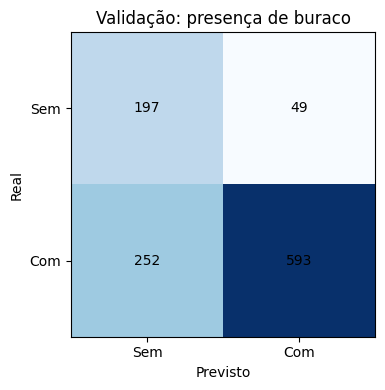

In [36]:
import yaml


PASTA_YOLO = PASTA_TREINO / 'yolo_300ep-3'

for arquivo in ['args.yaml', 'weights/best.pt']:
    if not (PASTA_YOLO / arquivo).is_file():
        raise FileNotFoundError(f'Arquivo não encontrado: {PASTA_YOLO / arquivo}')

args = yaml.safe_load((PASTA_YOLO / 'args.yaml').read_text(encoding='utf-8'))
assert args['imgsz'] == 640, 'O imgsz da avaliação (640) difere do usado no treino.'

modelo_yolo = YOLO(str(PASTA_YOLO / 'weights/best.pt'))
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

validacao = avaliar_divisao(modelo_yolo, 'validacao')
tabela_validacao = pd.DataFrame([validacao['metricas']], index=['validacao'])
tabela_validacao.to_csv(
    PASTA_RESULTADOS / 'metricas_validacao.csv',
    index_label='divisao',
)
display(tabela_validacao.round(4))

fig, eixo = plt.subplots(figsize=(4, 4))
plotar_matriz(eixo, validacao['matriz'], 'Validação: presença de buraco')
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / 'matriz_presenca_validacao.png', dpi=150)
plt.show()

## 8. Curvas de treinamento

Lemos o `results.csv` salvo pelo Ultralytics. A linha tracejada marca a época de maior
mAP50–95, critério de fitness da versão 8.4.198 usada no treinamento. A época é lida
da coluna `epoch`, sem somar nem subtrair 1. Não se repete o treinamento para gerar o gráfico.


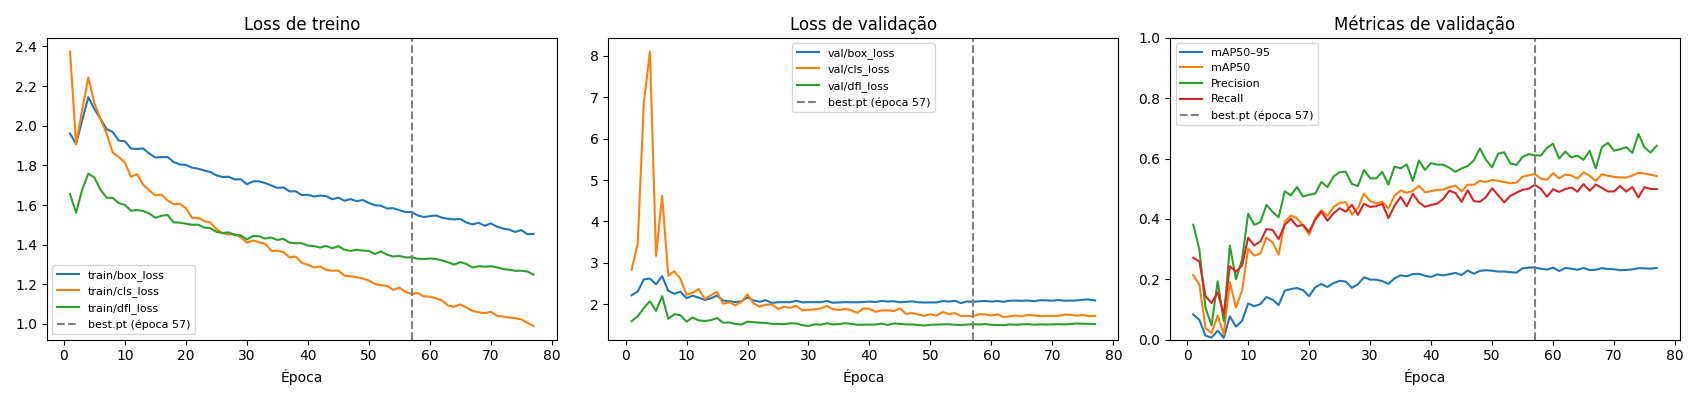

Melhor época pelo critério mAP50–95: 57 (de 77 executadas); corrigido a partir do results.csv salvo, sem repetir o treino.


In [37]:
curvas = pd.read_csv(PASTA_YOLO / 'results.csv')
curvas.columns = curvas.columns.str.strip()
curvas['fitness'] = curvas['metrics/mAP50-95(B)']
melhor_epoca = int(curvas['epoch'].iloc[int(curvas['fitness'].to_numpy().argmax())])

fig, eixos = plt.subplots(1, 3, figsize=(17, 4))
for coluna in ['train/box_loss', 'train/cls_loss', 'train/dfl_loss']:
    eixos[0].plot(curvas.epoch, curvas[coluna], label=coluna)
eixos[0].set_title('Loss de treino')
for coluna in ['val/box_loss', 'val/cls_loss', 'val/dfl_loss']:
    eixos[1].plot(curvas.epoch, curvas[coluna], label=coluna)
eixos[1].set_title('Loss de validação')
for coluna, rotulo in [('metrics/mAP50-95(B)', 'mAP50–95'), ('metrics/mAP50(B)', 'mAP50'),
                       ('metrics/precision(B)', 'Precision'), ('metrics/recall(B)', 'Recall')]:
    eixos[2].plot(curvas.epoch, curvas[coluna], label=rotulo)
eixos[2].set(title='Métricas de validação', ylim=(0, 1))
for eixo in eixos:
    eixo.axvline(melhor_epoca, color='gray', linestyle='--', label=f'best.pt (época {melhor_epoca})')
    eixo.set_xlabel('Época')
    eixo.legend(fontsize=8)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / 'curvas_treinamento.png', dpi=150)
plt.show()
print(f'best.pt vem da época {melhor_epoca} (de {len(curvas)} executadas).')

## 9. Análise de erros na validação


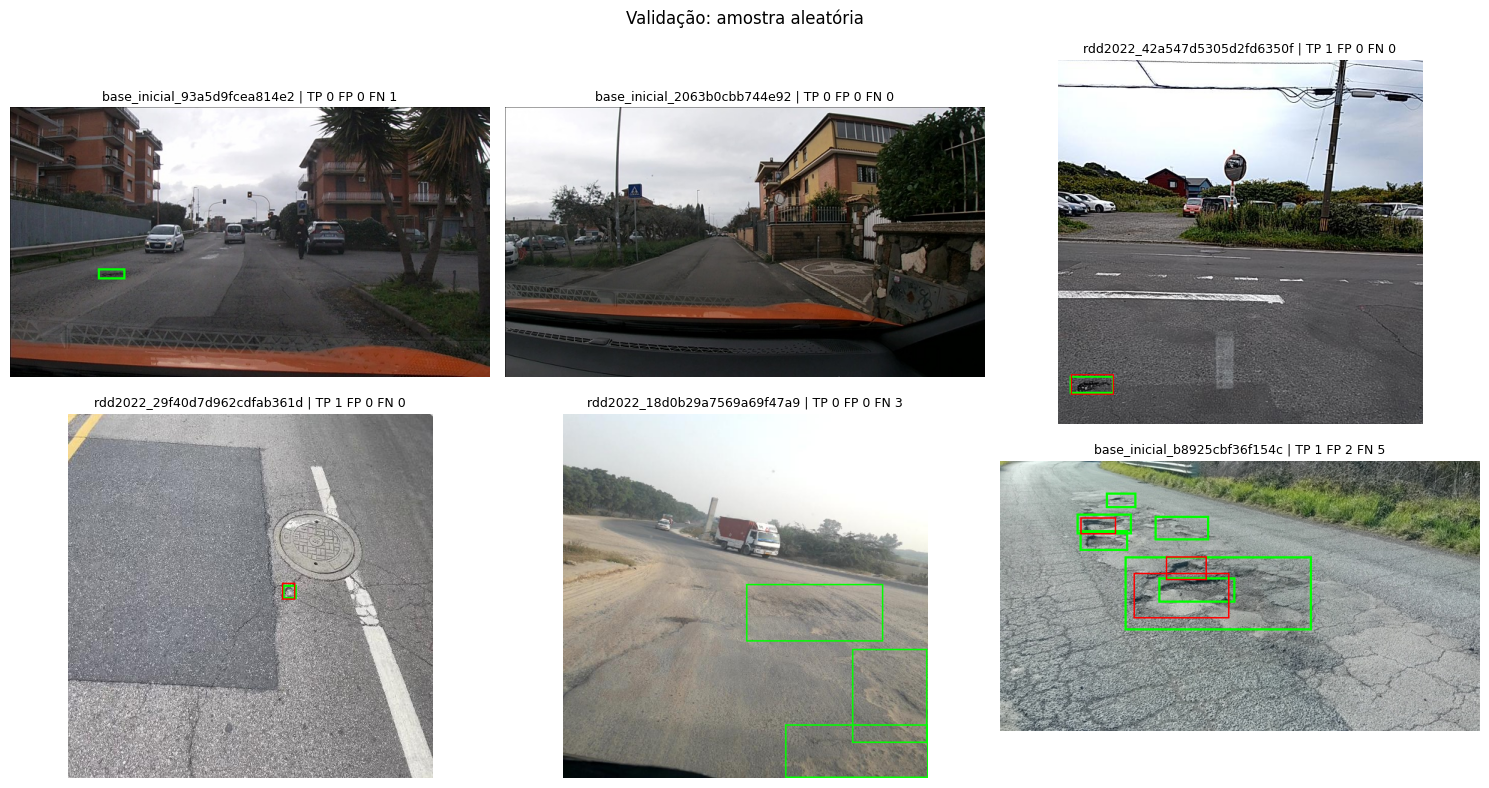

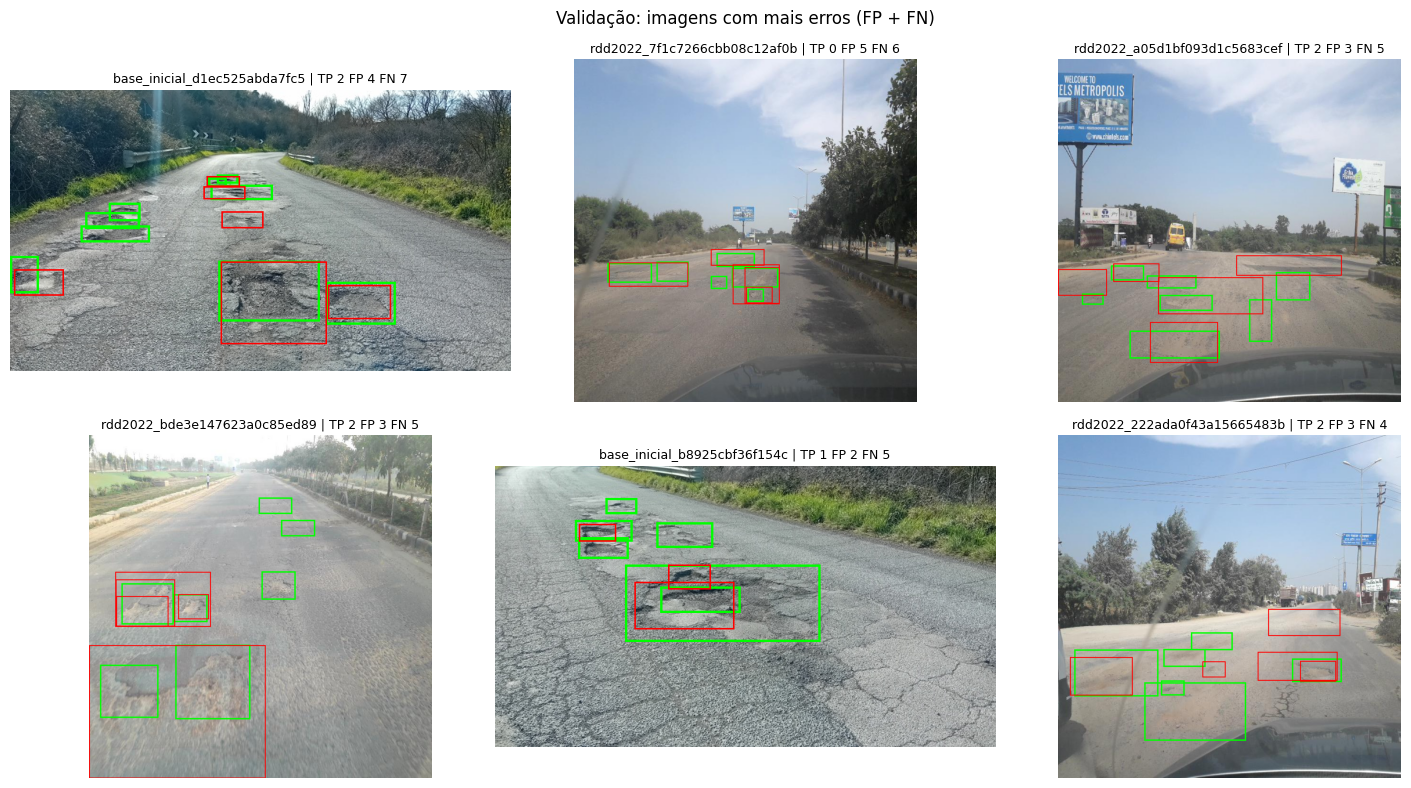

In [38]:
def mostrar_previsoes(resultado, indices, titulo, arquivo):
    """Desenha caixas reais (verde) e previstas (vermelho) das imagens escolhidas."""
    colunas = min(3, len(indices))
    linhas = -(-len(indices) // colunas)
    fig, eixos = plt.subplots(linhas, colunas, figsize=(5 * colunas, 4 * linhas), squeeze=False)
    for eixo in eixos.flat:
        eixo.axis('off')
    for eixo, i in zip(eixos.flat, indices):
        with Image.open(resultado['imagens'][i]) as arquivo_imagem:
            foto = arquivo_imagem.convert('RGB')
        desenho = ImageDraw.Draw(foto)
        for caixa in resultado['alvos'][i]['boxes']:
            desenho.rectangle(caixa.tolist(), outline='lime', width=3)
        previsto = resultado['previsoes'][i]
        for caixa, nota in zip(previsto['boxes'], previsto['scores']):
            if float(nota) >= CONFIANCA:
                desenho.rectangle(caixa.tolist(), outline='red', width=2)
        linha = resultado['por_imagem'].iloc[i]
        eixo.imshow(foto)
        eixo.set_title(f'{linha.arquivo[:28]} | TP {linha.tp} FP {linha.fp} FN {linha.fn}', fontsize=9)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.savefig(PASTA_RESULTADOS / arquivo, dpi=150)
    plt.show()


def mostrar_amostra_e_erros(resultado, nome, prefixo):
    """Mostra uma amostra aleatória e as imagens com mais erros (FP + FN) de uma divisão."""
    n = len(resultado['imagens'])
    mostrar_previsoes(resultado, random.Random(42).sample(range(n), min(6, n)),
                      f'{nome}: amostra aleatória', f'{prefixo}_amostra.png')
    erros = resultado['por_imagem'].assign(erros=lambda t: t.fp + t.fn).query('erros > 0').nlargest(6, 'erros')
    if erros.empty:
        print(f'{nome}: nenhuma imagem com erro na confiança {CONFIANCA}.')
    else:
        mostrar_previsoes(resultado, list(erros.index), f'{nome}: imagens com mais erros (FP + FN)',
                          f'{prefixo}_piores.png')


mostrar_amostra_e_erros(validacao, 'Validação', 'validacao')

## 11. Avaliação final no teste


Prevendo:   0%|          | 0/36 [00:00<?, ?it/s]

<ambiente-python>\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


,mAP50,mAP50_95,precision,recall,F1,TP,FP,FN,acuracia_presenca_imagem
validacao,0.5326,0.2319,0.6580,0.4620,0.5428,681,354,793,0.7241
teste,0.5243,0.2285,0.6518,0.4732,0.5483,335,179,373,0.7730


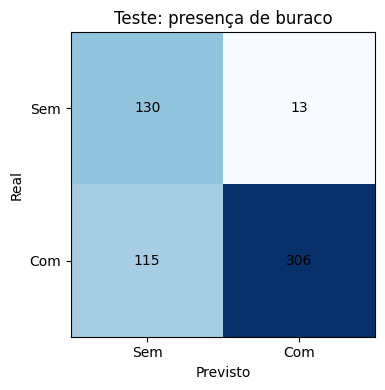

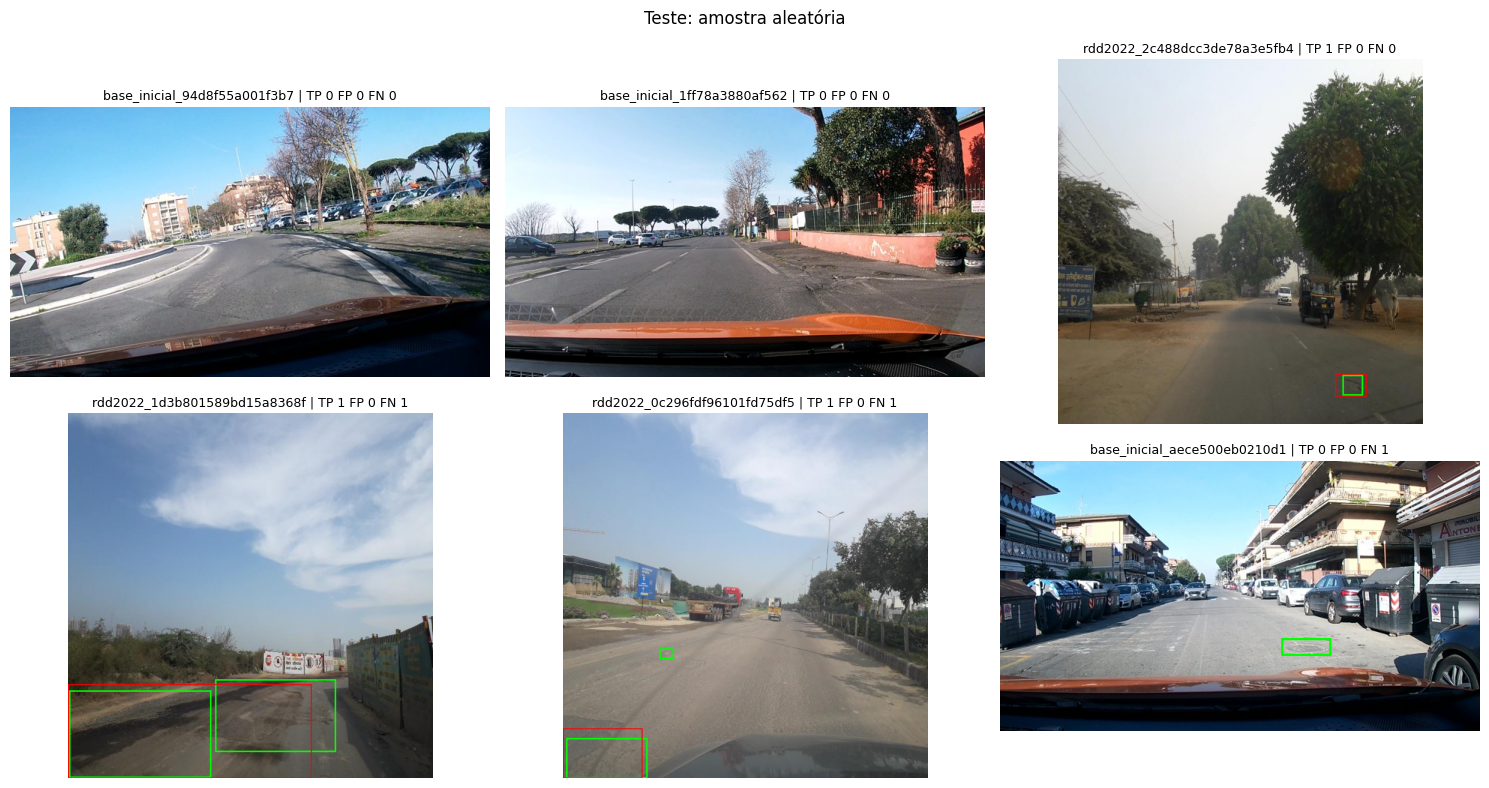

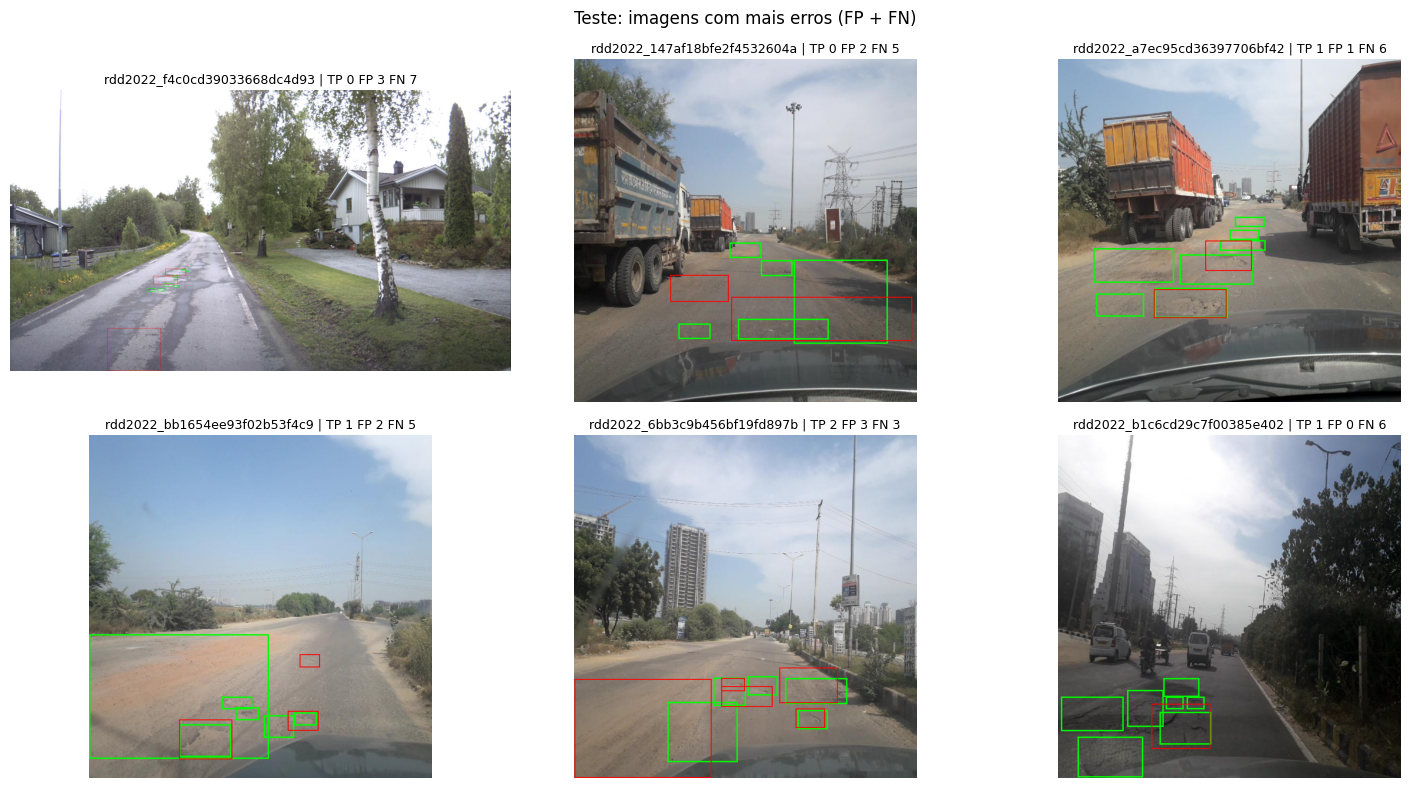

In [39]:
teste = avaliar_divisao(modelo_yolo, 'teste')
tabela_final = pd.concat([tabela_validacao, pd.DataFrame([teste['metricas']], index=['teste'])])
tabela_final.to_csv(PASTA_RESULTADOS / 'metricas.csv', index_label='divisao')
teste['por_imagem'].to_csv(PASTA_RESULTADOS / 'erros_por_imagem_teste.csv', index=False)
(PASTA_RESULTADOS / 'criterios.json').write_text(json.dumps({
    'confianca': CONFIANCA, 'iou_acerto': IOU_ACERTO, 'confianca_minima_previsao': 0.001,
    'iou_nms': 0.7, 'max_det': 300, 'imgsz': 640, 'map': 'torchmetrics, IoU 0,50 a 0,95, top-100 por imagem',
}, indent=2), encoding='utf-8')
display(tabela_final.round(4))

fig, eixo = plt.subplots(figsize=(4, 4))
plotar_matriz(eixo, teste['matriz'], 'Teste: presença de buraco')
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / 'matriz_presenca_teste.png', dpi=150)
plt.show()

mostrar_amostra_e_erros(teste, 'Teste', 'teste')

## 12. API de inferência

A implementação canônica está em `../api/app.py`. A célula seguinte apenas informa
os caminhos; não gera arquivos, não inicia o servidor e não executa treinamento.

A API carrega o checkpoint uma vez, faz aquecimento e oferece `GET /health` e
`POST /detect`. A análise exige sessão Supabase válida e aceita JPG, PNG ou WebP
de até 8 MB e 40 MP. Retorna caixas XYXY nos pixels da imagem orientada por EXIF.
Há uma inferência por vez, limite por usuário e CORS para Content-Type/Authorization.
As instruções de execução estão no README principal.


In [ ]:


api_canonica = PROJETO.parent / 'api' / 'app.py'
if not api_canonica.is_file():
    raise FileNotFoundError(f'API canônica não encontrada: {api_canonica}')
print(f'API autenticada: {api_canonica}')
print('Configure SUPABASE_URL e SUPABASE_PUBLISHABLE_KEY em api/.env.')
print('Na raiz do projeto: python -m uvicorn api.app:app --host 127.0.0.1 --port 8000 --workers 1 --env-file api/.env')
print('O checkpoint da API fica em api/models/best.pt, copiado do treinamento concluído.')


## 13. Resultados e limites

Métricas salvas da execução atual em `treinamentos/buracos_aug_nativo_01/avaliacao/metricas.csv`:

| Divisão | mAP50 | mAP50–95 | Precisão | Recall | F1 |
|---|---:|---:|---:|---:|---:|
| Validação | 0,5326 | 0,2319 | 0,6580 | 0,4620 | 0,5428 |
| Teste | 0,5243 | 0,2285 | 0,6518 | 0,4732 | 0,5483 |
